In [1]:
%pip install kagglehub

import kagglehub

# Download latest version
path = kagglehub.dataset_download("sergionefedov/global-football-transfer-market-2010-2026")

print("Path to dataset files:", path)

Note: you may need to restart the kernel to use updated packages.


c:\Users\dmikh\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 318k/318k [00:00<00:00, 1.63MB/s]


Extracting files...
Path to dataset files: C:\Users\dmikh\.cache\kagglehub\datasets\sergionefedov\global-football-transfer-market-2010-2026\versions\1


In [4]:
import os
import pandas as pd

# 1. See what files we have
print("Files in dataset:", os.listdir(path))

# 2. Load the two tables we need for Case File 1
df_clubs = pd.read_csv(os.path.join(path, "club_financials.csv"))
df_leagues = pd.read_csv(os.path.join(path, "league_metrics.csv"))

# 3. Look at the data
print("\n--- CLUB FINANCIALS ---")
display(df_clubs.head())

print("\n--- LEAGUE METRICS ---")
display(df_leagues.head())

Files in dataset: ['club_financials.csv', 'league_metrics.csv', 'player_market_values.csv', 'record_transfers.csv', 'transfers_history.csv']

--- CLUB FINANCIALS ---


,year,club_name,league,country,stadium_capacity,revenue_eur_m,wage_bill_eur_m,wages_to_revenue_pct,net_transfer_spend_eur_m,operating_profit_eur_m
0,2010,Manchester City,Premier_League,ENG,55000,154.4,76.9,49.8,40.9,-2.0
1,2011,Manchester City,Premier_League,ENG,55000,221.2,100.1,45.2,65.0,0.8
2,2012,Manchester City,Premier_League,ENG,55000,278.1,148.5,53.4,22.8,37.2
3,2013,Manchester City,Premier_League,ENG,55000,330.4,196.3,59.4,93.1,-41.5
4,2014,Manchester City,Premier_League,ENG,55000,401.8,243.6,60.6,64.6,-6.9



--- LEAGUE METRICS ---


,year,league,country,num_teams,total_revenue_eur_m,avg_attendance,avg_ticket_eur,foreign_players_pct
0,2010,Premier_League,ENG,20,2450.0,40147,65,65
1,2011,Premier_League,ENG,20,2858.0,37109,65,65
2,2012,Premier_League,ENG,20,3186.0,41821,65,65
3,2013,Premier_League,ENG,20,3620.0,42198,65,65
4,2014,Premier_League,ENG,20,3975.0,39567,65,65


In [5]:
df_clubs.info()

<class 'pandas.DataFrame'>
RangeIndex: 884 entries, 0 to 883
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   year                      884 non-null    int64  
 1   club_name                 884 non-null    str    
 2   league                    884 non-null    str    
 3   country                   884 non-null    str    
 4   stadium_capacity          884 non-null    int64  
 5   revenue_eur_m             884 non-null    float64
 6   wage_bill_eur_m           884 non-null    float64
 7   wages_to_revenue_pct      884 non-null    float64
 8   net_transfer_spend_eur_m  884 non-null    float64
 9   operating_profit_eur_m    884 non-null    float64
dtypes: float64(5), int64(2), str(3)
memory usage: 69.2 KB


In [14]:
total_revenue = df_clubs.groupby("club_name")["revenue_eur_m"].sum().sort_values(ascending=False)
display(total_revenue)

club_name
Real Madrid                 11140.7
FC Barcelona                10535.9
Manchester United            9573.8
Bayern Munich                9513.3
Manchester City              9169.5
Paris Saint-Germain          8688.6
Liverpool                    8495.6
Chelsea                      7595.5
Arsenal                      7379.3
Tottenham                    6374.3
Juventus                     5807.3
Borussia Dortmund            5344.6
Atletico Madrid              4616.3
Everton                      4560.0
West Ham                     4532.8
Inter Milan                  4516.9
AC Milan                     4282.8
Bayer Leverkusen             3803.2
Napoli                       3682.5
Roma                         3432.6
Newcastle United             3394.7
RB Leipzig                   2855.1
Benfica                      2474.2
Sevilla                      2399.6
Fiorentina                   2394.2
Eintracht Frankfurt          2385.7
Borussia Monchengladbach     2383.7
Atalanta          

In [16]:
revenue_by_league = df_clubs.groupby("league")["revenue_eur_m"].sum().sort_values(ascending=False)
display(revenue_by_league)

league
Premier_League      63414.5
La_Liga             38162.6
Serie_A             28861.0
Bundesliga          28645.1
Ligue_1             16326.4
Liga_Portugal        5602.7
Eredivisie           4145.3
Super_Lig            3452.6
Saudi_Pro_League     2807.9
MLS                  2086.8
Name: revenue_eur_m, dtype: float64

In [17]:
print("CLUB FINANCIALS COLUMNS & TYPES:")
print(df_clubs.dtypes)
print("\nShape:", df_clubs.shape)

print("\n" + "=" * 40 + "\n")

print("LEAGUE METRICS COLUMNS & TYPES:")
print(df_leagues.dtypes)
print("\nShape:", df_leagues.shape)

CLUB FINANCIALS COLUMNS & TYPES:
year                          int64
club_name                       str
league                          str
country                         str
stadium_capacity              int64
revenue_eur_m               float64
wage_bill_eur_m             float64
wages_to_revenue_pct        float64
net_transfer_spend_eur_m    float64
operating_profit_eur_m      float64
dtype: object

Shape: (884, 10)


LEAGUE METRICS COLUMNS & TYPES:
year                     int64
league                     str
country                    str
num_teams                int64
total_revenue_eur_m    float64
avg_attendance           int64
avg_ticket_eur           int64
foreign_players_pct      int64
dtype: object

Shape: (170, 8)


KeyError: 'Column not found: ticket_price_eur'

,club_name,revenue_increase_eur_m,wage_increase_eur_m,revenue_growth_after_wage_increase_eur_m
33,Paris Saint-Germain,362.5,239.2,123.3
1,Manchester United,271.9,143.0,128.9
12,Atletico Madrid,237.7,88.4,149.3
2,Liverpool,370.4,215.4,155.0
11,FC Barcelona,283.7,117.6,166.1
10,Real Madrid,349.3,173.6,175.7
18,Bayern Munich,265.7,89.7,176.0
4,Arsenal,339.3,156.6,182.7
0,Manchester City,447.3,257.8,189.5
5,Tottenham,348.0,145.6,202.4


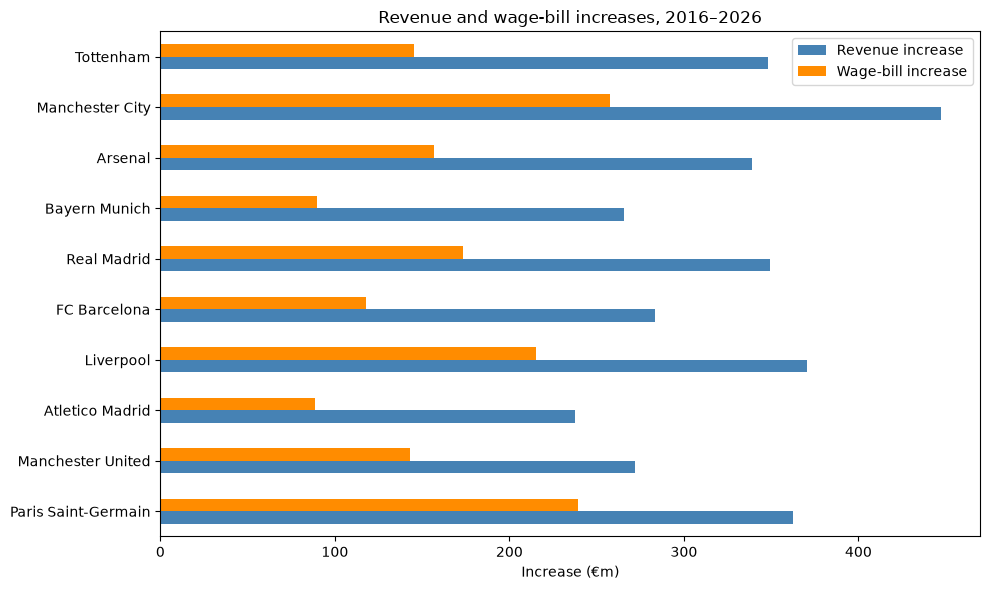

In [21]:
import matplotlib.pyplot as plt

start_year = latest_year - 10

start = df_clubs.loc[
    df_clubs["year"] == start_year,
    ["club_name", "revenue_eur_m", "wage_bill_eur_m"]
].rename(columns={
    "revenue_eur_m": "revenue_start",
    "wage_bill_eur_m": "wages_start"
})

end = df_clubs.loc[
    df_clubs["year"] == latest_year,
    ["club_name", "revenue_eur_m", "wage_bill_eur_m"]
].rename(columns={
    "revenue_eur_m": "revenue_end",
    "wage_bill_eur_m": "wages_end"
})

growth_vs_wages = start.merge(end, on="club_name")
growth_vs_wages["revenue_increase_eur_m"] = (
    growth_vs_wages["revenue_end"] - growth_vs_wages["revenue_start"]
)
growth_vs_wages["wage_increase_eur_m"] = (
    growth_vs_wages["wages_end"] - growth_vs_wages["wages_start"]
)
growth_vs_wages["revenue_growth_after_wage_increase_eur_m"] = (
    growth_vs_wages["revenue_increase_eur_m"]
    - growth_vs_wages["wage_increase_eur_m"]
)

top_clubs = growth_vs_wages.nlargest(
    10, "revenue_growth_after_wage_increase_eur_m"
).sort_values("revenue_growth_after_wage_increase_eur_m")

display(top_clubs[[
    "club_name",
    "revenue_increase_eur_m",
    "wage_increase_eur_m",
    "revenue_growth_after_wage_increase_eur_m"
]].round(1))

ax = top_clubs.set_index("club_name")[
    ["revenue_increase_eur_m", "wage_increase_eur_m"]
].plot(kind="barh", figsize=(10, 6), color=["steelblue", "darkorange"])

ax.set_title(f"Revenue and wage-bill increases, {start_year}–{latest_year}")
ax.set_xlabel("Increase (€m)")
ax.set_ylabel("")
ax.legend(["Revenue increase", "Wage-bill increase"])
plt.tight_layout()
plt.show()

In [33]:
display(df_leagues[df_leagues["league"] == "Premier_League"].sort_values("total_revenue_eur_m", ascending=False).head(25))

,year,league,country,num_teams,total_revenue_eur_m,avg_attendance,avg_ticket_eur,foreign_players_pct
16,2026,Premier_League,ENG,20,8233.0,38094,65,65
15,2025,Premier_League,ENG,20,7452.0,40347,65,65
14,2024,Premier_League,ENG,20,7062.0,38961,65,65
13,2023,Premier_League,ENG,20,6816.0,38220,65,65
12,2022,Premier_League,ENG,20,6317.0,38176,65,65
11,2021,Premier_League,ENG,20,5502.0,11496,65,65
9,2019,Premier_League,ENG,20,5181.0,38649,65,65
8,2018,Premier_League,ENG,20,5001.0,39522,65,65
10,2020,Premier_League,ENG,20,4884.0,11110,65,65
7,2017,Premier_League,ENG,20,4761.0,38959,65,65
